# PrintGPT A4 alignment: a reproducible walkthrough

This notebook lets you **see and measure** the complete geometry pipeline before a physical printer is involved:

1. inspect the canonical 210 × 297 mm / 300 DPI coordinate system;
2. generate the true-size calibration PDF and its raster preview;
3. detect four ArUco markers in one distorted document;
4. estimate the homography and rectify the page;
5. compare the recovered transform with exact synthetic ground truth;
6. inspect the 30-case synthetic benchmark and 10 SmartDoc-derived camera cases;
7. run the automated test suite; and
8. try a scan or photograph of your own.

This notebook covers only calibration, detection, rectification, and evaluation. It intentionally does **not** perform image generation, printer control, or scanning automation.

**How to use it:** choose the project interpreter at `.venv\Scripts\python.exe`, then use **Run All**. The heavier dataset rebuilding cells have switches that default to `False` because verified artifacts already exist.

In [1]:
from __future__ import annotations

import json
import subprocess
import sys
import tempfile
from dataclasses import asdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def find_project_root() -> Path:
    # Works whether Jupyter starts in the project or in notebooks/.
    starts = [Path.cwd()]
    for start in starts:
        for candidate in (start, *start.parents):
            if (candidate / "pyproject.toml").is_file() and (
                candidate / "src" / "printgpt_alignment"
            ).is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Could not find the PrintGPT project root")


PROJECT_ROOT = find_project_root()
SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from printgpt_alignment.benchmark import run_benchmark
from printgpt_alignment.calibration_page import (
    write_calibration_pdf,
    write_calibration_png,
)
from printgpt_alignment.detection import detect_and_rectify
from printgpt_alignment.document import load_document_page
from printgpt_alignment.geometry import DEFAULT_LAYOUT, mm_to_px, px_to_mm
from printgpt_alignment.metrics import draw_alignment_overlay, evaluate_alignment
from printgpt_alignment.smartdoc import prepare_smartdoc_benchmark
from printgpt_alignment.synthetic import generate_synthetic_benchmark

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("Project root:", PROJECT_ROOT)
print("Python:", sys.executable)
print("OpenCV:", cv2.__version__)

Project root: C:\Users\saroy\Codes\PrintGPT
Python: c:\Users\saroy\Codes\PrintGPT\.venv\Scripts\python.exe
OpenCV: 5.0.0


## 1. Canonical page geometry

The origin is the **top-left paper edge**. `x` grows to the right and `y` grows downward. Physical layout values remain in millimetres; conversion to pixels happens only at the raster boundary.

At 300 DPI, 1 mm is about 11.81 pixels. A4 rounds to 2480 × 3508 pixels. The four 14 mm markers sit 12 mm from the paper edges. Their distinct IDs encode both page identity and orientation. The 10 mm dashed boundary is a conservative protected area for printers that cannot reach the paper edge.

In [2]:
layout = DEFAULT_LAYOUT

page_table = pd.DataFrame(
    {
        "value": [
            layout.layout_id,
            f"{layout.page_width_mm:.0f} × {layout.page_height_mm:.0f} mm",
            f"{layout.raster_width_px} × {layout.raster_height_px} px",
            f"{layout.dpi:.0f}",
            f"{mm_to_px(1, layout.dpi):.4f} px",
            f"{px_to_mm(1, layout.dpi):.4f} mm",
            f"{layout.protected_margin_mm:.1f} mm",
        ]
    },
    index=[
        "Layout ID",
        "Physical page",
        "Canonical raster",
        "Resolution (DPI)",
        "1 mm",
        "1 pixel",
        "Protected margin",
    ],
)

marker_table = pd.DataFrame(
    [
        {
            "ID": marker.marker_id,
            "role": marker.role,
            "x_mm": marker.bounds_mm.x,
            "y_mm": marker.bounds_mm.y,
            "size_mm": marker.bounds_mm.width,
        }
        for marker in layout.markers
    ]
)

display(page_table)
display(Markdown("**Marker specification**"))
display(marker_table)

,value
Layout ID,PRINTGPT-A4-CAL-V1
Physical page,210 × 297 mm
Canonical raster,2480 × 3508 px
Resolution (DPI),300
1 mm,11.8110 px
1 pixel,0.0847 mm
Protected margin,10.0 mm


**Marker specification**

,ID,role,x_mm,y_mm,size_mm
0,10,top_left,12.0,12.0,14.0
1,11,top_right,184.0,12.0,14.0
2,12,bottom_right,184.0,271.0,14.0
3,13,bottom_left,12.0,271.0,14.0


## 2. Generate the calibration page

The PDF is vector-based so marker edges remain sharp. Always print it as **Actual size / 100%** with every “fit”, “shrink”, or borderless scaling option disabled. The PNG is a 300-DPI reference and convenient preview; the PDF is the preferred printable source.

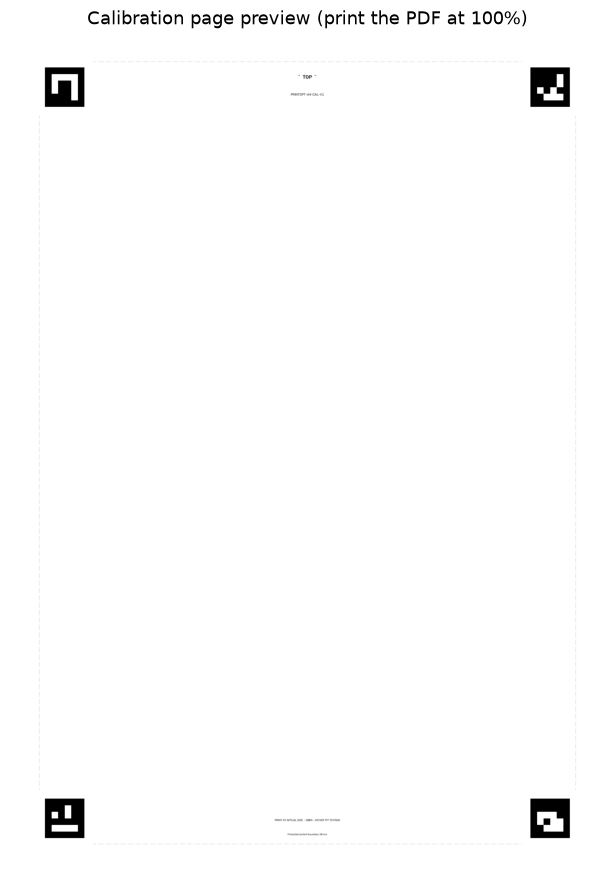

PDF: C:\Users\saroy\Codes\PrintGPT\output\pdf\printgpt_a4_calibration_v1.pdf
PNG: C:\Users\saroy\Codes\PrintGPT\output\png\printgpt_a4_calibration_v1_300dpi.png
Raster shape (height, width): (3508, 2480)


In [3]:
pdf_path = write_calibration_pdf(
    PROJECT_ROOT / "output" / "pdf" / "printgpt_a4_calibration_v1.pdf"
)
png_path = write_calibration_png(
    PROJECT_ROOT / "output" / "png" / "printgpt_a4_calibration_v1_300dpi.png"
)

calibration = cv2.imread(str(png_path), cv2.IMREAD_GRAYSCALE)
fig, ax = plt.subplots(figsize=(7, 9.9))
ax.imshow(calibration, cmap="gray", vmin=0, vmax=255)
ax.set_title("Calibration page preview (print the PDF at 100%)")
ax.axis("off")
plt.show()

print("PDF:", pdf_path)
print("PNG:", png_path)
print("Raster shape (height, width):", calibration.shape)

## 3. Prepare or reuse the offline synthetic benchmark

The generator makes 30 deterministic captures with known homographies. Valid cases combine rotation, translation, scale, perspective, blur, noise, shadow, JPEG compression, and real FUNSD document backgrounds. Eight invalid cases deliberately crop, occlude, or severely degrade the markers.

Set `REBUILD_SYNTHETIC = True` when you want to regenerate the dataset from its fixed seed. Leaving it `False` keeps this normal Run All fast.

In [4]:
SYNTHETIC_ROOT = PROJECT_ROOT / "artifacts" / "synthetic"
SYNTHETIC_REPORT_ROOT = PROJECT_ROOT / "artifacts" / "benchmark"
SYNTHETIC_MANIFEST = SYNTHETIC_ROOT / "manifest.json"
SYNTHETIC_REPORT = SYNTHETIC_REPORT_ROOT / "benchmark_report.json"
SCAN_ROOT = PROJECT_ROOT / "data" / "scanned_docs" / "funsd"

REBUILD_SYNTHETIC = False
RERUN_SYNTHETIC_BENCHMARK = False

scan_paths = sorted(SCAN_ROOT.glob("*.png")) + sorted(SCAN_ROOT.glob("*.jpg"))
if REBUILD_SYNTHETIC or not SYNTHETIC_MANIFEST.exists():
    SYNTHETIC_MANIFEST = generate_synthetic_benchmark(
        SYNTHETIC_ROOT,
        count=30,
        seed=20261014,
        scan_paths=scan_paths,
    )
    print("Regenerated:", SYNTHETIC_MANIFEST)
else:
    print("Reusing:", SYNTHETIC_MANIFEST)

if RERUN_SYNTHETIC_BENCHMARK or not SYNTHETIC_REPORT.exists():
    SYNTHETIC_REPORT = run_benchmark(SYNTHETIC_ROOT, SYNTHETIC_REPORT_ROOT)
    print("Recomputed:", SYNTHETIC_REPORT)
else:
    print("Reusing:", SYNTHETIC_REPORT)

synthetic_manifest = json.loads(SYNTHETIC_MANIFEST.read_text(encoding="utf-8"))
print(
    f"Cases: {synthetic_manifest['case_count']} "
    f"({synthetic_manifest['expected_valid_count']} valid, "
    f"{synthetic_manifest['expected_invalid_count']} invalid)"
)

Reusing: C:\Users\saroy\Codes\PrintGPT\artifacts\synthetic\manifest.json
Reusing: C:\Users\saroy\Codes\PrintGPT\artifacts\benchmark\benchmark_report.json
Cases: 30 (22 valid, 8 invalid)


## 4. Watch one case move through detection and rectification

The detector accepts only a unique set of IDs 10–13. It refines marker corners, obtains an initial transform from marker centres, associates the physical corner of every marker, and fits a robust homography from 16 correspondences. It then checks marker size, scale consistency, inlier count, residual error, visible page area, convexity, and an overall confidence score.

The marker-colour legend below is **red 10**, **green 11**, **blue 12**, **orange 13**.

In [5]:
demo_case = next(
    case
    for case in synthetic_manifest["cases"]
    if case["expected_accept"] and case["category"] == "perspective"
)
demo_path = SYNTHETIC_ROOT / demo_case["image"]
demo_image = cv2.imread(str(demo_path), cv2.IMREAD_GRAYSCALE)
if demo_image is None:
    raise OSError(f"Could not read {demo_path}")

detection = detect_and_rectify(demo_image)
diagnostics = pd.Series(
    {
        "case": demo_case["case_id"],
        "accepted": detection.accepted,
        "reason": detection.reason,
        "confidence": round(detection.confidence, 4),
        "detected IDs": detection.detected_ids,
        "orientation": detection.orientation_degrees,
        "RANSAC inliers": f"{detection.inlier_count}/16",
        "marker RMSE (px)": detection.reprojection_rmse_px,
        "marker max inlier error (px)": detection.reprojection_inlier_max_px,
    },
    name="value",
)
display(diagnostics.to_frame())

,value
case,case_06
accepted,True
reason,accepted
confidence,0.9544
detected IDs,"(10, 11, 12, 13)"
orientation,0
RANSAC inliers,16/16
marker RMSE (px),0.699409
marker max inlier error (px),1.179103


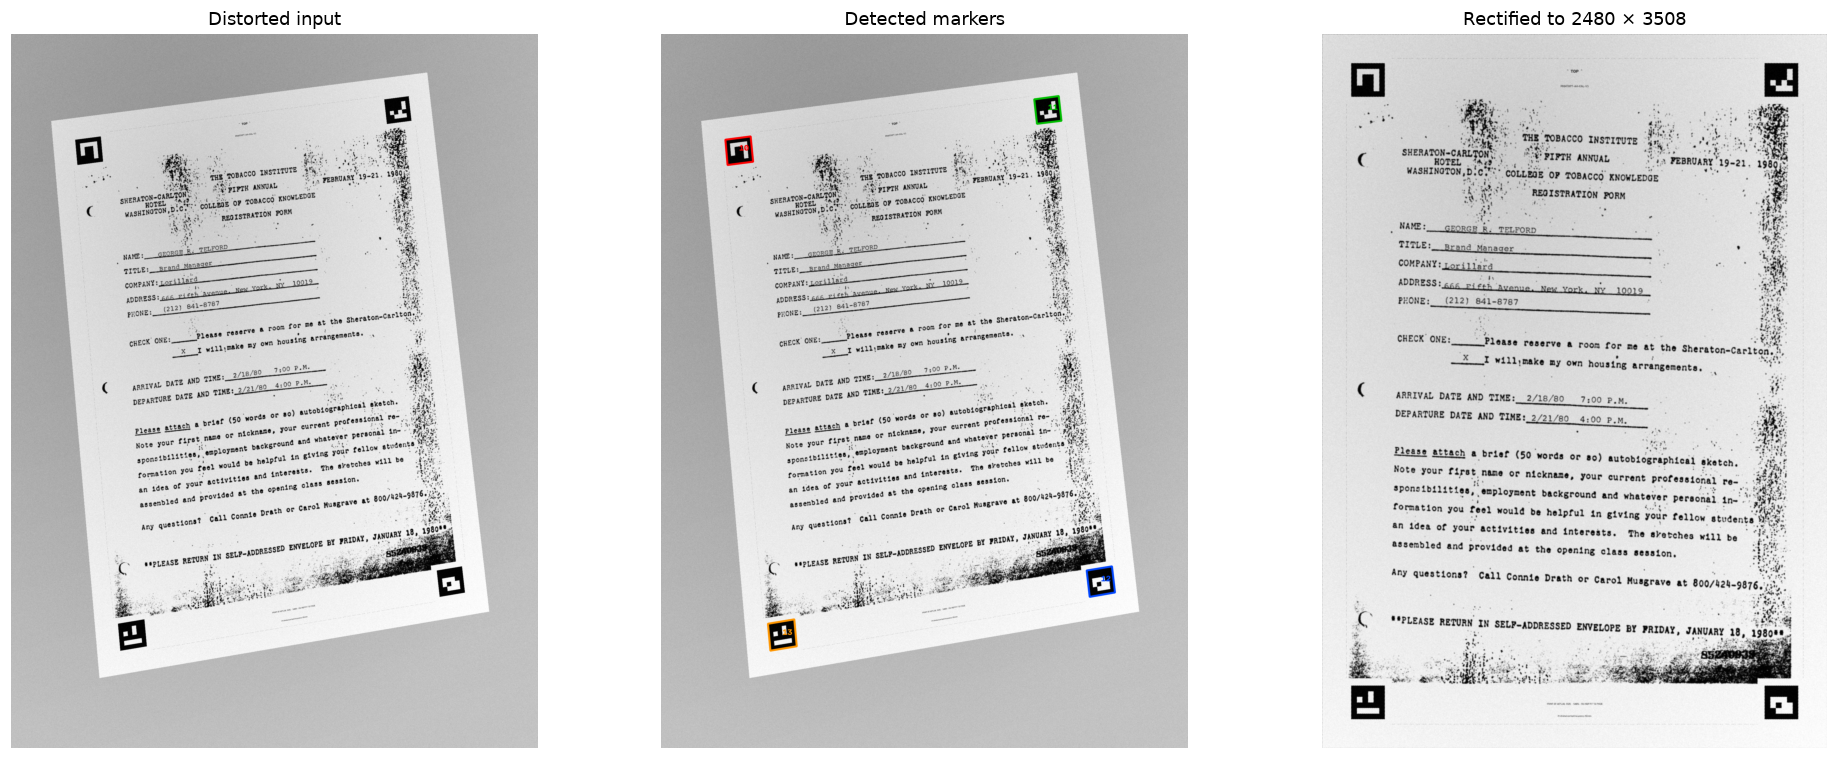

In [6]:
marked = cv2.cvtColor(demo_image, cv2.COLOR_GRAY2BGR)
marker_colours = {
    10: (0, 0, 255),
    11: (0, 190, 0),
    12: (255, 70, 0),
    13: (0, 150, 255),
}
for marker_id, corners in (detection.source_marker_corners or {}).items():
    polygon = np.rint(corners).astype(np.int32)
    cv2.polylines(marked, [polygon], True, marker_colours[marker_id], 5, cv2.LINE_AA)
    center = tuple(np.rint(corners.mean(axis=0)).astype(int))
    cv2.putText(
        marked,
        str(marker_id),
        center,
        cv2.FONT_HERSHEY_SIMPLEX,
        1.0,
        marker_colours[marker_id],
        3,
        cv2.LINE_AA,
    )

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
axes[0].imshow(demo_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Distorted input")
axes[1].imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
axes[1].set_title("Detected markers")
if detection.warped is not None:
    axes[2].imshow(detection.warped, cmap="gray", vmin=0, vmax=255)
    axes[2].set_title("Rectified to 2480 × 3508")
else:
    axes[2].text(0.5, 0.5, detection.reason, ha="center", va="center", wrap=True)
    axes[2].set_title("Rejected")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Measure the transform independently

Marker residuals alone are not enough: they measure the same points used to fit the transform. For the real quality result we map a separate **9 × 13 page-wide grid (117 points)** through the exact ground-truth transform and then back through the recovered transform.

In the overlay, expected locations are green, recovered locations are magenta, and orange line segments expose their separation. A perfect recovery makes the two point sets overlap.

,pixels,millimetres
Mean,0.809,0.0685
RMSE,0.841,0.0712
95th percentile,1.211,0.1026
Maximum,1.404,0.1188


Corner errors (mm): [0.0618, 0.0896, 0.1188, 0.0382]
Independent evaluation points: 117


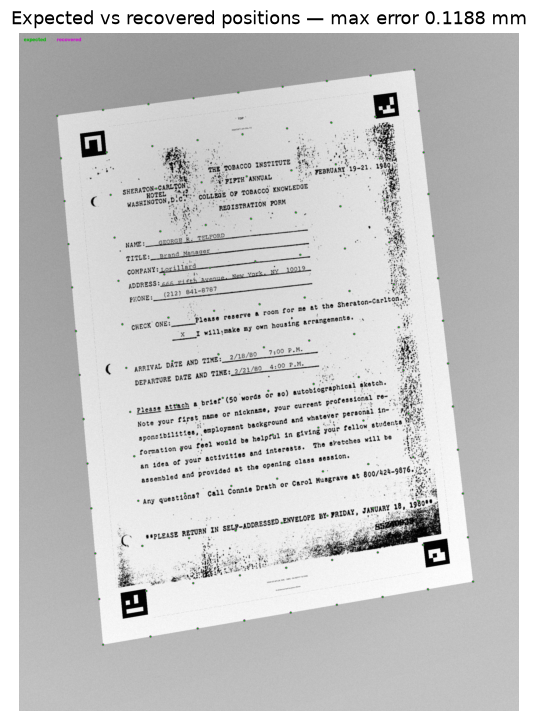

In [7]:
if detection.source_to_canonical is None:
    raise RuntimeError(f"Demo case was not measurable: {detection.reason}")

ground_truth = np.asarray(demo_case["canonical_to_source"], dtype=np.float64)
quality = evaluate_alignment(ground_truth, detection.source_to_canonical)
overlay = draw_alignment_overlay(
    demo_image,
    ground_truth,
    detection.source_to_canonical,
)

quality_table = pd.DataFrame(
    {
        "pixels": [
            quality.mean_error_px,
            quality.rmse_px,
            quality.p95_error_px,
            quality.max_error_px,
        ],
        "millimetres": [
            quality.mean_error_mm,
            quality.rmse_mm,
            quality.p95_error_mm,
            quality.max_error_mm,
        ],
    },
    index=["Mean", "RMSE", "95th percentile", "Maximum"],
)
display(quality_table.style.format({"pixels": "{:.3f}", "millimetres": "{:.4f}"}))
print("Corner errors (mm):", [round(value, 4) for value in quality.corner_errors_mm])
print("Independent evaluation points:", quality.evaluation_point_count)

fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
ax.set_title(f"Expected vs recovered positions — max error {quality.max_error_mm:.4f} mm")
ax.axis("off")
plt.show()

## 6. Evaluate all 30 synthetic cases

Success means all expected-valid cases are accepted, all deliberately invalid cases are rejected, and the maximum independent geometric error of every accepted valid case stays below **0.5 mm**.

In [8]:
synthetic_report = json.loads(SYNTHETIC_REPORT.read_text(encoding="utf-8"))
synthetic_summary = pd.Series(synthetic_report["summary"], name="result").to_frame()
display(synthetic_summary)

synthetic_cases = pd.DataFrame(synthetic_report["cases"])
columns = [
    "case_id",
    "category",
    "expected_accept",
    "accepted",
    "confidence",
    "max_error_mm",
    "reason",
]
display(synthetic_cases.reindex(columns=columns).round(4))

,result
total_cases,30
expected_valid_cases,22
expected_invalid_cases,8
accepted_valid_cases,22
valid_failure_rate,0.0
invalid_false_accept_rate,0.0
mean_alignment_error_mm,0.068557
maximum_alignment_error_mm,0.127229
target_max_error_mm,0.5
target_met,True


,case_id,category,expected_accept,accepted,confidence,max_error_mm,reason
0,case_01,affine,True,True,0.9674,0.0920,accepted
1,case_02,affine,True,True,0.9675,0.0961,accepted
2,case_03,affine,True,True,0.9723,0.0971,accepted
3,case_04,affine,True,True,0.9605,0.1012,accepted
4,case_05,affine,True,True,0.9650,0.1005,accepted
5,case_06,perspective,True,True,0.9544,0.1188,accepted
6,case_07,perspective,True,True,0.9576,0.0993,accepted
7,case_08,perspective,True,True,0.9632,0.1272,accepted
8,case_09,perspective,True,True,0.9524,0.1112,accepted
9,case_10,perspective,True,True,0.9576,0.1092,accepted


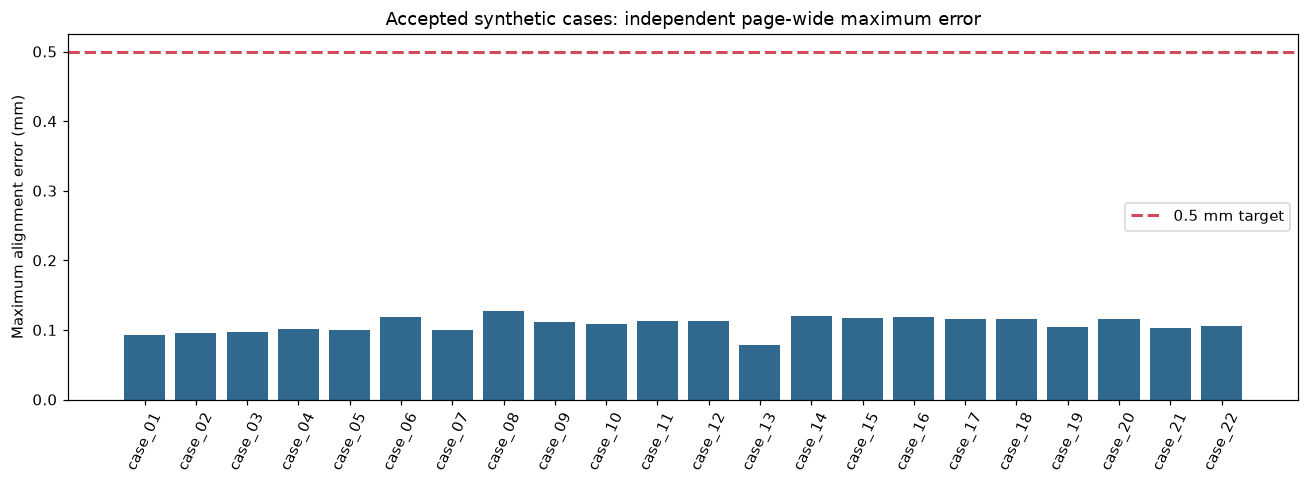

PASS: acceptance/rejection behaviour is correct and the 0.5 mm target is met.


In [9]:
accepted_valid = synthetic_cases[
    synthetic_cases["expected_accept"] & synthetic_cases["accepted"]
].copy()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(accepted_valid["case_id"], accepted_valid["max_error_mm"], color="#31688e")
ax.axhline(0.5, color="#d1495b", linestyle="--", linewidth=2, label="0.5 mm target")
ax.set_ylabel("Maximum alignment error (mm)")
ax.set_title("Accepted synthetic cases: independent page-wide maximum error")
ax.tick_params(axis="x", rotation=65)
ax.legend()
plt.tight_layout()
plt.show()

summary = synthetic_report["summary"]
assert summary["valid_failure_rate"] == 0.0
assert summary["invalid_false_accept_rate"] == 0.0
assert summary["target_met"] is True
print("PASS: acceptance/rejection behaviour is correct and the 0.5 mm target is met.")

### Inspect any benchmark case

Change `CASE_TO_VIEW` to `case_01` … `case_30`. Accepted cases show the saved expected-vs-recovered overlay and rectified page. Rejected cases show the input and rejection reason, which is exactly what we want for missing or unreliable marker geometry.

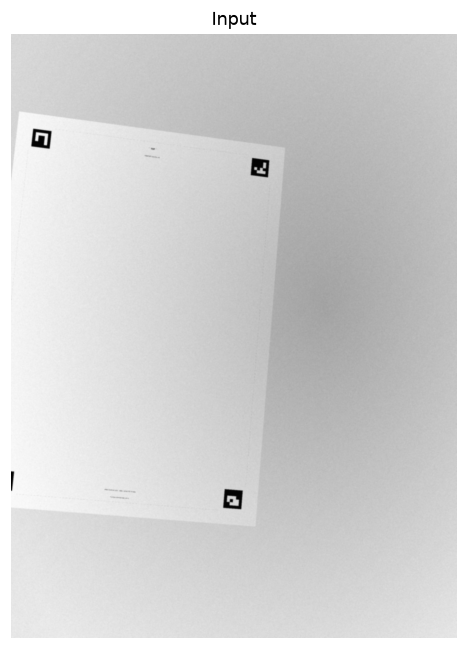

,value
case_id,case_23
category,compound
expected_accept,False
accepted,False
reason,missing expected markers: [13]
confidence,0.0
orientation_degrees,None
marker_reprojection_rmse_px,None
marker_reprojection_max_px,None
marker_reprojection_inlier_max_px,None


In [10]:
CASE_TO_VIEW = "case_23"  # first deliberately invalid case; try case_06 too


def show_synthetic_case(case_id: str) -> None:
    manifest_case = next(case for case in synthetic_manifest["cases"] if case["case_id"] == case_id)
    report_case = next(case for case in synthetic_report["cases"] if case["case_id"] == case_id)
    source = cv2.imread(str(SYNTHETIC_ROOT / manifest_case["image"]), cv2.IMREAD_GRAYSCALE)
    if source is None:
        raise OSError(manifest_case["image"])

    panels = [("Input", source, "gray")]
    overlay_path = SYNTHETIC_REPORT_ROOT / "overlays" / f"{case_id}.jpg"
    rectified_path = SYNTHETIC_REPORT_ROOT / "rectified" / f"{case_id}.jpg"
    if overlay_path.exists():
        panels.append(("Expected vs recovered", cv2.imread(str(overlay_path)), "bgr"))
    if rectified_path.exists():
        panels.append(("Rectified", cv2.imread(str(rectified_path), cv2.IMREAD_GRAYSCALE), "gray"))

    fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 6))
    axes = np.atleast_1d(axes)
    for ax, (title, image, colour) in zip(axes, panels, strict=True):
        if colour == "bgr":
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    display(pd.Series(report_case, name="value").to_frame())


show_synthetic_case(CASE_TO_VIEW)

## 7. SmartDoc-derived camera cases

These ten cases use real SmartDoc camera scenes and annotated perspective quadrilaterals. The calibration page and markers are inserted digitally into the annotated document plane so the ground truth remains exact.

This is more realistic than purely generated backgrounds, but it is still **not a replacement for the next physical print/photograph/scan test**, because the markers themselves were not physically printed in SmartDoc.

Set `REBUILD_SMARTDOC = True` to reconstruct the ten cases from `sampleDataset.tar.gz`.

,result
total_cases,10
expected_valid_cases,10
expected_invalid_cases,0
accepted_valid_cases,10
valid_failure_rate,0.0
invalid_false_accept_rate,0.0
mean_alignment_error_mm,0.106103
maximum_alignment_error_mm,0.418469
target_max_error_mm,0.5
target_met,True


,case_id,accepted,confidence,mean_error_mm,max_error_mm
0,smartdoc_01,True,0.7591,0.1461,0.3647
1,smartdoc_02,True,0.7555,0.0419,0.0826
2,smartdoc_03,True,0.8448,0.1143,0.3181
3,smartdoc_04,True,0.8404,0.1007,0.3239
4,smartdoc_05,True,0.7631,0.0784,0.2351
5,smartdoc_06,True,0.7656,0.1641,0.3935
6,smartdoc_07,True,0.8162,0.0494,0.1877
7,smartdoc_08,True,0.6920,0.1164,0.2173
8,smartdoc_09,True,0.7112,0.1394,0.4185
9,smartdoc_10,True,0.7731,0.1104,0.2350


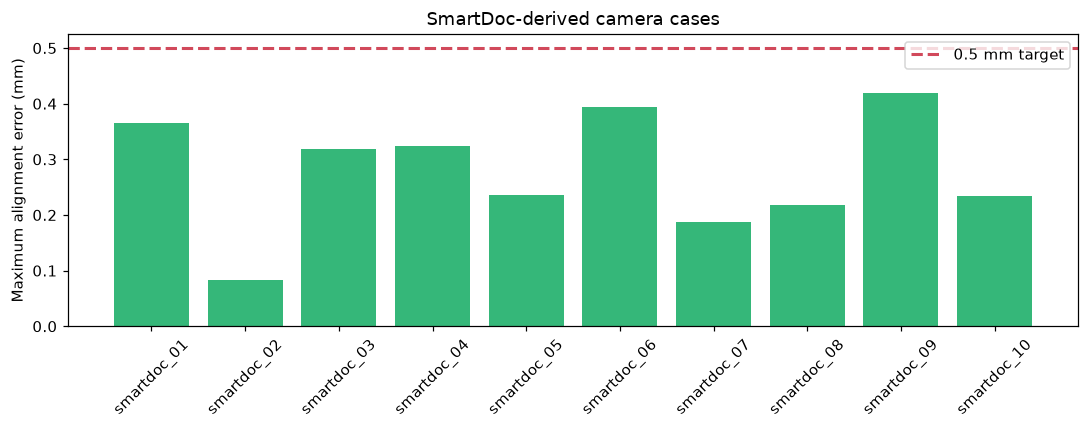

In [11]:
SMARTDOC_ARCHIVE = Path.home() / "Downloads" / "sampleDataset.tar.gz"
SMARTDOC_ROOT = PROJECT_ROOT / "artifacts" / "smartdoc"
SMARTDOC_REPORT_ROOT = PROJECT_ROOT / "artifacts" / "smartdoc_benchmark"
SMARTDOC_MANIFEST = SMARTDOC_ROOT / "manifest.json"
SMARTDOC_REPORT = SMARTDOC_REPORT_ROOT / "benchmark_report.json"

REBUILD_SMARTDOC = False
RERUN_SMARTDOC_BENCHMARK = False

if REBUILD_SMARTDOC:
    if not SMARTDOC_ARCHIVE.is_file():
        raise FileNotFoundError(
            f"Set SMARTDOC_ARCHIVE to the downloaded archive first: {SMARTDOC_ARCHIVE}"
        )
    SMARTDOC_MANIFEST = prepare_smartdoc_benchmark(
        SMARTDOC_ARCHIVE,
        SMARTDOC_ROOT,
        count=10,
    )
    print("Regenerated:", SMARTDOC_MANIFEST)

if RERUN_SMARTDOC_BENCHMARK or not SMARTDOC_REPORT.exists():
    if not SMARTDOC_MANIFEST.exists():
        print("SmartDoc artifacts are absent; set REBUILD_SMARTDOC = True after setting the archive path.")
    else:
        SMARTDOC_REPORT = run_benchmark(SMARTDOC_ROOT, SMARTDOC_REPORT_ROOT)
        print("Recomputed:", SMARTDOC_REPORT)

if SMARTDOC_REPORT.exists():
    smartdoc_report = json.loads(SMARTDOC_REPORT.read_text(encoding="utf-8"))
    display(pd.Series(smartdoc_report["summary"], name="result").to_frame())
    smartdoc_cases = pd.DataFrame(smartdoc_report["cases"])
    display(
        smartdoc_cases[
            ["case_id", "accepted", "confidence", "mean_error_mm", "max_error_mm"]
        ].round(4)
    )

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(smartdoc_cases["case_id"], smartdoc_cases["max_error_mm"], color="#35b779")
    ax.axhline(0.5, color="#d1495b", linestyle="--", linewidth=2, label="0.5 mm target")
    ax.set_ylabel("Maximum alignment error (mm)")
    ax.set_title("SmartDoc-derived camera cases")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
    plt.tight_layout()
    plt.show()

## 8. Run the automated tests

The notebook is the visual teaching and evaluation surface. The regular pytest suite remains the fast regression guard for conversions, page layout, rendering, detection, rejection paths, benchmark metrics, and SmartDoc preparation.

In [12]:
artifacts_root = PROJECT_ROOT / "artifacts"
artifacts_root.mkdir(exist_ok=True)
with tempfile.TemporaryDirectory(prefix="pytest_notebook_", dir=artifacts_root) as basetemp:
    completed = subprocess.run(
        [sys.executable, "-m", "pytest", "-q", f"--basetemp={basetemp}"],
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
        timeout=300,
    )
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
if completed.returncode != 0:
    raise RuntimeError(f"pytest failed with exit code {completed.returncode}")

.....................                                                    [100%]
21 passed in 1.02s



## 9. Try your own PDF, scan, or photograph

Set a PDF, PNG, JPG, or TIFF path below and rerun the cell. For a PDF, choose a 1-based page number and rendering DPI. The page is rasterized first because ArUco detection and homography estimation operate on pixels.

The cell reports the acceptance decision, confidence, orientation, residuals, and - when accepted - the canonical rectified page. No ground-truth millimetre error is available for an ordinary document; measuring that requires a controlled physical target, which is the next validation stage.

In [ ]:
USER_CAPTURE_PATH = r"C:\Users\saroy\Downloads\0773_001.pdf"
# Examples:
# USER_CAPTURE_PATH = str(Path.home() / "Downloads" / "scan.pdf")
# USER_CAPTURE_PATH = str(Path.home() / "Pictures" / "calibration_photo.jpg")

USER_CAPTURE_PAGE = 1  # Human-friendly page number for PDFs.
USER_CAPTURE_DPI = 300

if USER_CAPTURE_PATH is None:
    print("Set USER_CAPTURE_PATH to a PDF, scan, or photograph, then rerun this cell.")
else:
    user_path = Path(USER_CAPTURE_PATH).expanduser()
    user_image = load_document_page(
        user_path,
        page_index=USER_CAPTURE_PAGE - 1,
        dpi=USER_CAPTURE_DPI,
    )
    print(
        f"Loaded {user_path.name} page {USER_CAPTURE_PAGE} "
        f"as {user_image.shape[1]} x {user_image.shape[0]} pixels"
    )

    user_result = detect_and_rectify(user_image)
    display(pd.Series(user_result.to_dict(), name="value").drop(
        labels=["source_to_canonical", "canonical_to_source", "source_marker_corners"],
        errors="ignore",
    ).to_frame())

    panel_count = 2 if user_result.warped is not None else 1
    fig, axes = plt.subplots(1, panel_count, figsize=(7 * panel_count, 8))
    axes = np.atleast_1d(axes)
    axes[0].imshow(cv2.cvtColor(user_image, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Your input")
    axes[0].axis("off")
    if user_result.warped is not None:
        axes[1].imshow(cv2.cvtColor(user_result.warped, cv2.COLOR_BGR2RGB))
        axes[1].set_title("Recovered canonical A4")
        axes[1].axis("off")
    plt.tight_layout()
    plt.show()


## Reading the result

The current offline gate is deliberately simple and strict:

- expected-valid synthetic cases must be accepted;
- incomplete/unreliable cases must be rejected;
- maximum independent page-wide error must stay below **0.5 mm**;
- the overlay should not show a spatial bias that a single summary number hides.

Once those remain stable, the next experiment is a small physical set: print the PDF at 100%, verify marker size with a ruler, collect flatbed scans plus several phone angles, and photograph a millimetre grid or measured control points. That physical set—not SmartDoc—will reveal printer scaling, paper feed skew, lens distortion, and scanner calibration effects.